## CLASIFICACIÓN

En este fichero se va a realizar la primera tarea del proyecto. En ella se aplicará el modelo de RandomForest de árboles con la intención de clasificar la situación final del estudiante entre las clases de **Abandono**, **Matriculado** y **Graduado**.
A continuación, se analizará el resultado obtenido con la intención de anticipar por sus características cual será la situación final del estudiante.

In [13]:
# Importamos las librería
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import math

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

## 1. Carga y exploración de los datos

Comenzamos por importar los datos y acabar de limpiar los datos. Además, haremos una primera visión de la variable objetivo para entenderla

In [14]:
df = pd.read_csv("../rendimiento_estudiantes_limpio.csv")
print(df["objetivo"].value_counts())

objetivo
graduado       2209
abandono       1421
matriculado     794
Name: count, dtype: int64


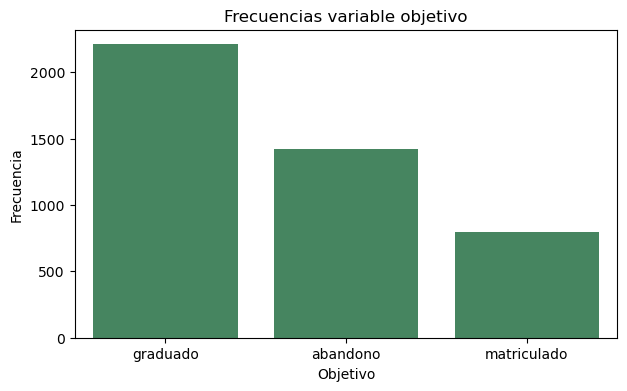

Porcentajes de aparición de cada una de las variables: 


,frecuencia,porcentaje
objetivo,,
graduado,2209,49.93
abandono,1421,32.12
matriculado,794,17.95


In [15]:
plt.figure(figsize=(7,4))
sns.countplot(df, x="objetivo",order=df["objetivo"].value_counts().index, color="#3b905e")
plt.title("Frecuencias variable objetivo")
plt.xlabel("Objetivo")
plt.ylabel("Frecuencia")
plt.show()

print("Porcentajes de aparición de cada una de las variables: ")
objetivo_counts = df["objetivo"].value_counts()
objetivo_pct = (df["objetivo"].value_counts(normalize=True) * 100).round(2)
resumen_objetivo = pd.concat([objetivo_counts, objetivo_pct], axis=1)
resumen_objetivo.columns = ["frecuencia", "porcentaje"]
resumen_objetivo


Se puede observar tanto en el gráfico como en los valores que hay desbalanceo entre las clases pero tampoco muchísimo, es un desbalanceo moderado. La clase predomiennate es graduado seguido por abandono y finalizando por matriculado. Esto puede significar que el modelo puede que prediga mejor la clase de graduado que el resto, por lo tanto, no sería buena idea evaluar el modelo únicamente con accuracy pues gran parte del rendimiento puede ser consecuencia de acertar bien la clase mayoritaria. Para intentar evaluar de manera más completo usaré también F1 macro, classification report y matriz de confusión.

In [16]:
# A continuación, comprobamos valores faltantes
nulos=df.isna().sum()
print("Número de variables con valores faltantes: ", (nulos>0).sum())


Número de variables con valores faltantes:  0


Como se puede observar, no hay valores faltantes en ninguna de las variables. 

In [17]:
X = df.drop(columns=["objetivo"]).copy()
y = df["objetivo"].copy()

col_cat = X.select_dtypes(include=["object", "category"]).columns.to_list()
col_num = X.select_dtypes(include=["int64", "float64"]).columns.to_list()

print(f"Variables categóricas: {len(col_cat)}")
print(f"Variables numéricas: {len(col_num)}")

Variables categóricas: 16
Variables numéricas: 19


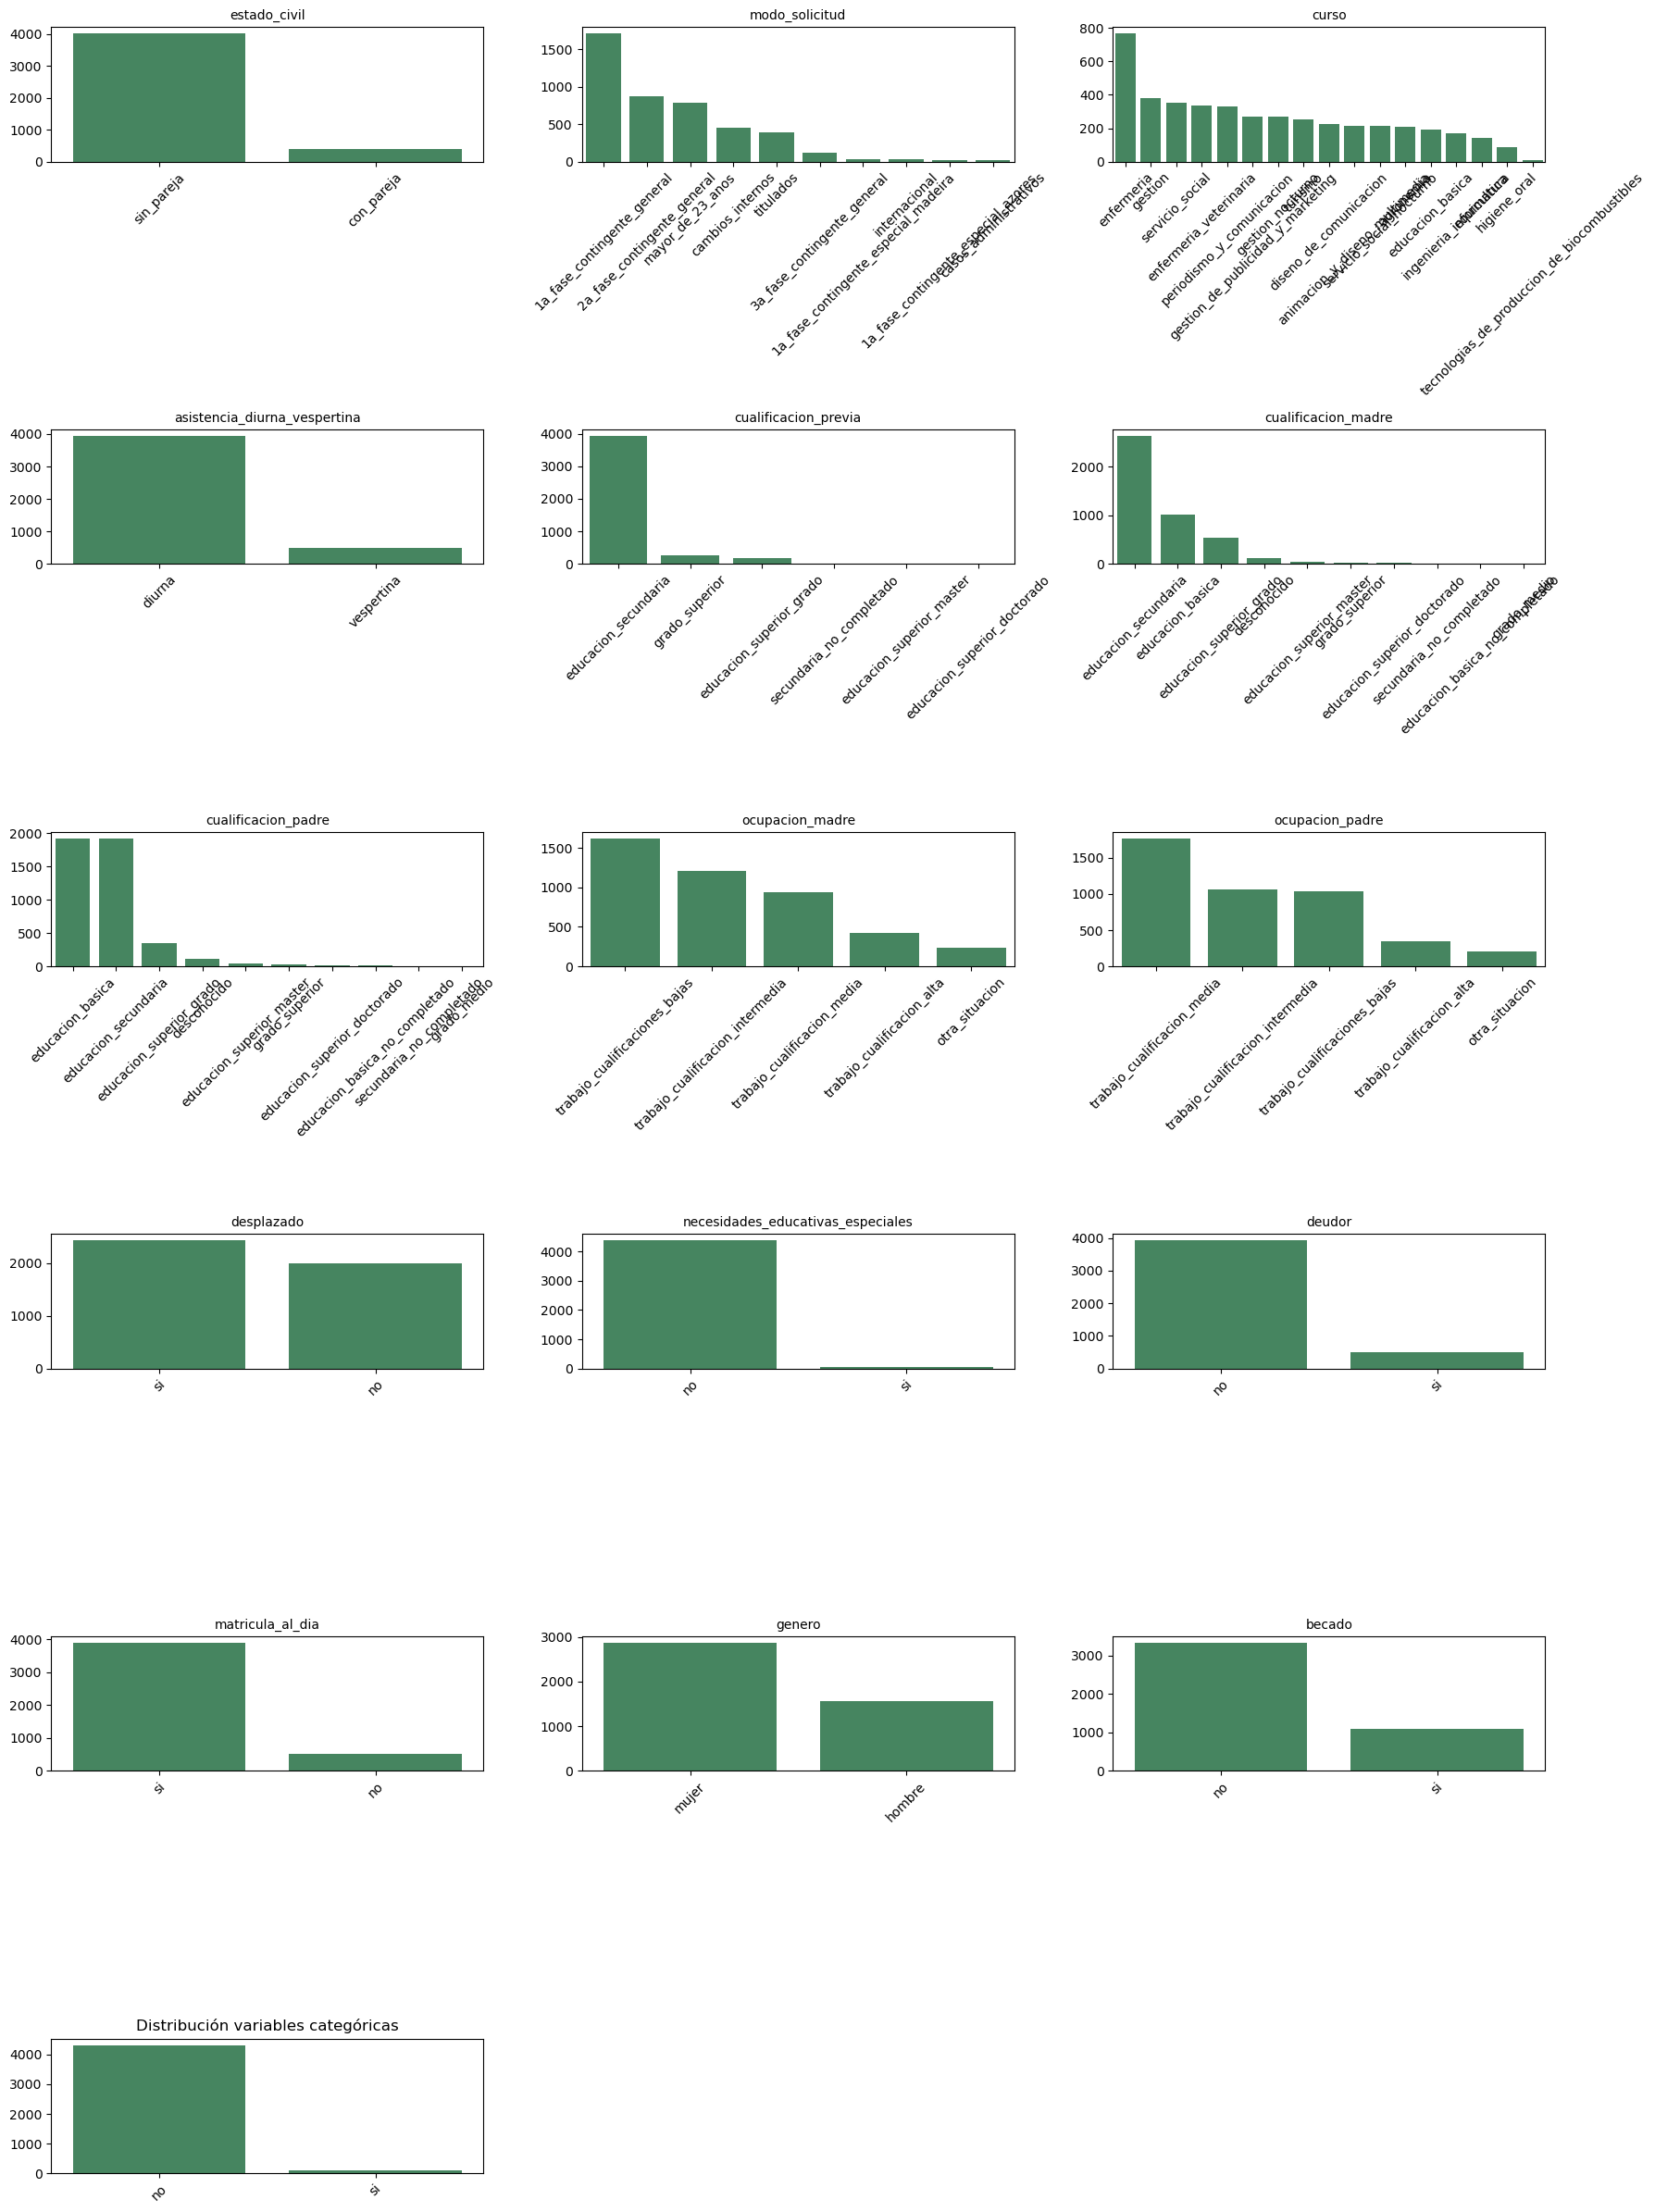

In [18]:
# Mostrar frecuencias de variables categóricas
n_cols = 3  # número de columnas en la cuadrícula
n_rows = math.ceil(len(col_cat) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(col_cat):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=axes[i], color="#3b905e")
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

# borrar ejes vacíos si sobran
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
    
plt.title('Distribución variables categóricas')
plt.tight_layout()
plt.show()

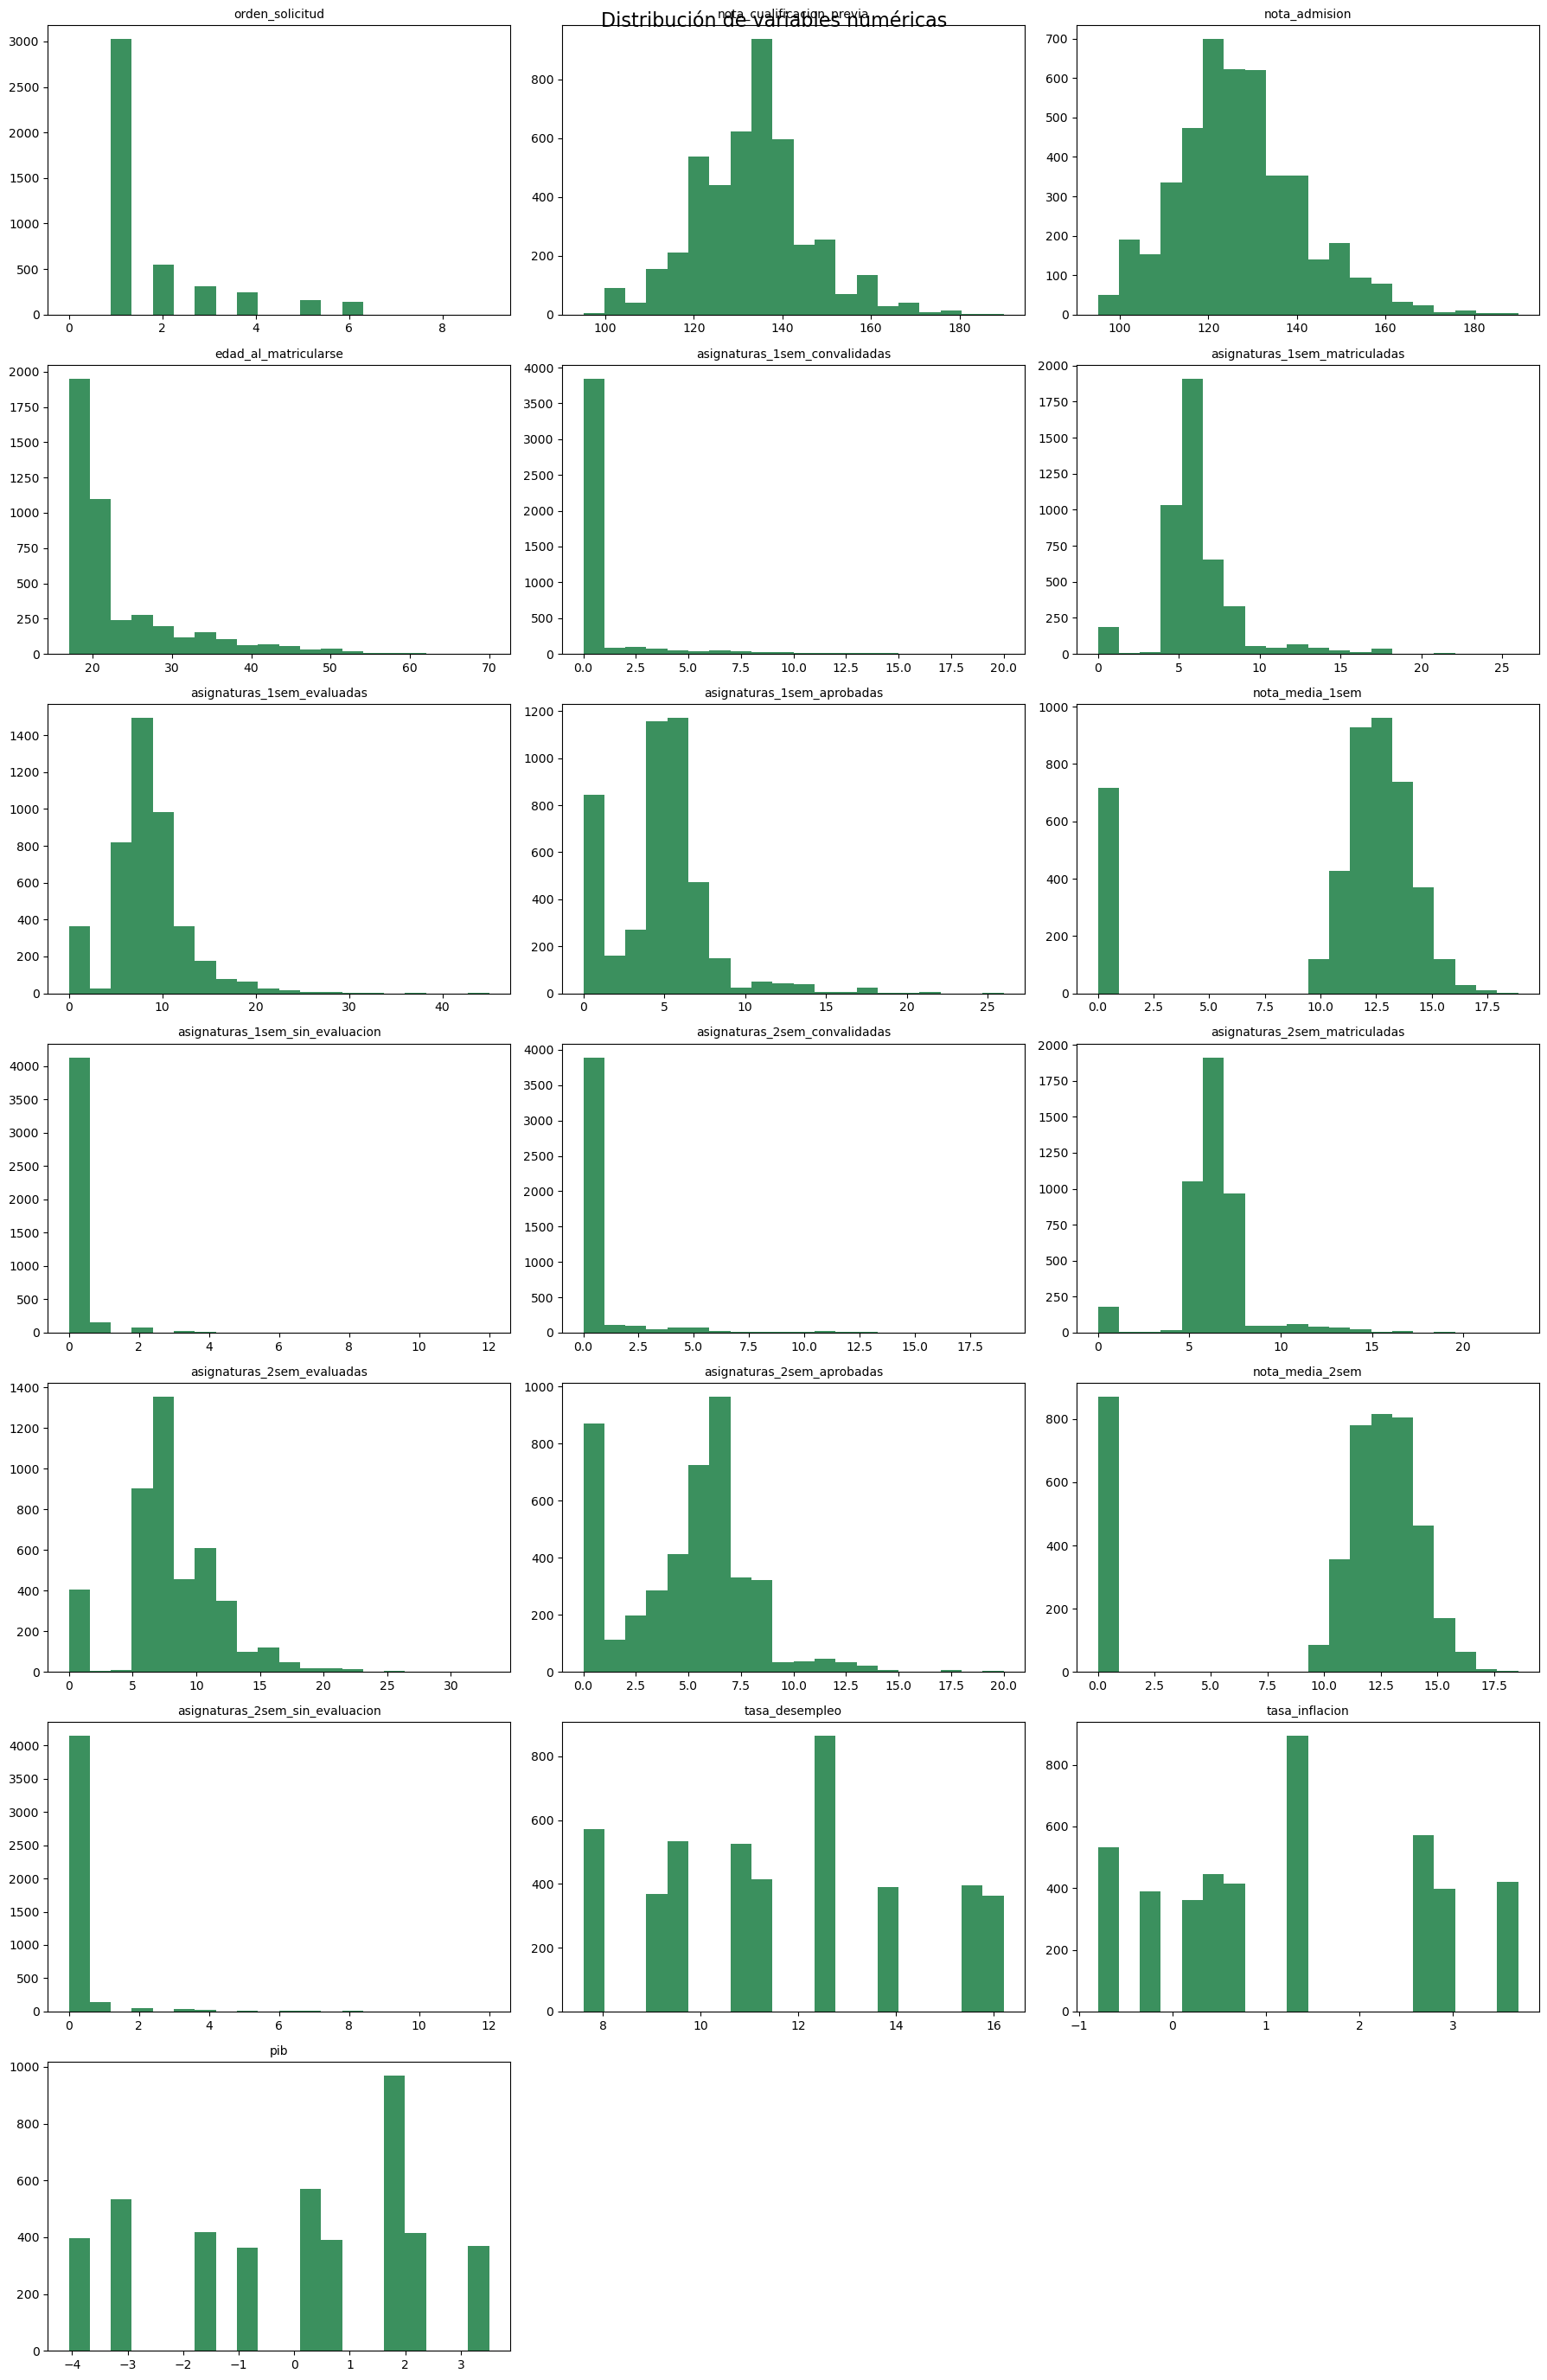

In [19]:
# Distribución variables numéricas

n_cols = 3
n_rows = math.ceil(len(col_num) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(col_num):
    axes[i].hist(df[col], bins=20, color="#3b905e")
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Distribución de variables numéricas", fontsize=16)
plt.tight_layout()
plt.show()

## 2. Codificación de las variables categóricas y separación train/test

Debido a que RandomForest no trabaja directamente con texto, vamos a codificar las variables categóricas usando one-hot encoding. 

In [20]:
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first")

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=55, stratify=y)

X_train_num = X_train[col_num]
X_test_num = X_test[col_num]

X_train_cat = pd.DataFrame(
    ohe.fit_transform(X_train[col_cat]),
    columns=ohe.get_feature_names_out(col_cat),
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    ohe.transform(X_test[col_cat]),
    columns=ohe.get_feature_names_out(col_cat),
    index=X_test.index
)

X_train = pd.concat([X_train_num, X_train_cat], axis=1)
X_test = pd.concat([X_test_num, X_test_cat], axis=1)

c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## 3. Ajuste de los hiperparámetros: 
**Número de árboles** y **máxima profundidad**

La selección se hará priorizando F1 macro ya que es la medida que trata a las clases por igual y es más adecuada ante la presencia de desbalanceo

In [22]:
resultados = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=55)

n_estimadores = [100,200,300]
max_depth = [None, 10,20,30]

for n in n_estimadores:
    for prof in max_depth:
        modelo = RandomForestClassifier(n_estimators=n, max_depth=prof, random_state=55, n_jobs=-1)

        
        # Al hacer macro lo que hago es calcular la media por cada una de las clases y luego se calcula la medoa simple,
        #   dando el mismo peso a todas las calses. Esto interesa porque el dataset es un poco desbalanceado.
        f1 = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="f1_macro")
        accuracy = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="accuracy")
        
        resultados.append({"n_estimators": n,
            "max_depth": "None" if prof is None else prof,
            "f1_macro_mean": f1.mean(),
            "f1_macro_std": f1.std(),
            "accuracy_mean":accuracy.mean(),
            "accuracy_std": accuracy.std()})

# Elegimos en función de f1_macro debido a que tengo un problema de varias clases y estas no están perfectamente balanceadas.
# Accuracy aunque pueda parecer alta puede que el modelo esté fallando por esta alta dimensionalidad, sin mebargo, la añado para facilitar
# la interpretación global del modelo
resultados_df = pd.DataFrame(resultados)
print(resultados_df.sort_values(by="f1_macro_mean", ascending=False).head(10))


    n_estimators max_depth  f1_macro_mean  f1_macro_std  accuracy_mean  \
0            100      None       0.685162      0.012297       0.774510   
3            100        30       0.684106      0.011879       0.774227   
6            200        20       0.681208      0.019461       0.773662   
2            100        20       0.680638      0.014770       0.773379   
4            200      None       0.680584      0.019593       0.772246   
7            200        30       0.679549      0.019466       0.771964   
11           300        30       0.677156      0.017823       0.770270   
8            300      None       0.677045      0.018463       0.770270   
10           300        20       0.676107      0.018624       0.772249   
9            300        10       0.661382      0.014805       0.768292   

    accuracy_std  
0       0.009595  
3       0.009585  
6       0.011986  
2       0.012623  
4       0.014091  
7       0.014188  
11      0.012630  
8       0.012567  
10      0.0113

Una vez hecha la exploración de que hiperparámetros son mejores tomar teniendo en cuenta los valores obtenidos por el score F1 macro, llegamos a la conclusión de que el mejor algoritmo es aquel cuya profundida del árbol es 30 con un total de 300 estimadores.

In [23]:
valores_mejores = resultados_df.iloc[0]
mejor_n = int(valores_mejores["n_estimators"])
mejor_depth = None if valores_mejores["max_depth"] == "None" else int(valores_mejores["max_depth"])

print("La mejor configuración por lo tanto es: ")
print(valores_mejores)

La mejor configuración por lo tanto es: 
n_estimators          100
max_depth            None
f1_macro_mean    0.685162
f1_macro_std     0.012297
accuracy_mean     0.77451
accuracy_std     0.009595
Name: 0, dtype: object


## 4. Comparación de dos modelos

Debido a que la variable objetivo está desbalanceada pudiendo hacer que no sea un modelo lo suficientemente eficiente, comparo dos variantes: usando `class_weight="balanced"` y sin usarla 

In [24]:
modelo_base = RandomForestClassifier(n_estimators=300, max_depth=30, random_state=55)
modelo_balanced = RandomForestClassifier(n_estimators=300, max_depth=30, random_state=55, class_weight="balanced")

modelo_base.fit(X_train, y_train)
modelo_balanced.fit(X_train, y_train)

predictions_base = modelo_base.predict(X_test)
predictions_balances = modelo_balanced.predict(X_test)

comparacion_modelos = pd.DataFrame([
    {
        "modelo": "RandomForest base",
        "accuracy": accuracy_score(y_test, predictions_base),
        "f1_macro": f1_score(y_test, predictions_base, average="macro"),
    },
    {
        "modelo": "RandomForest balanced",
        "accuracy": accuracy_score(y_test, predictions_balances),
        "f1_macro": f1_score(y_test, predictions_balances, average="macro"),
    },
]).sort_values("f1_macro", ascending=False)

comparacion_modelos

,modelo,accuracy,f1_macro
0,RandomForest base,0.771751,0.696217
1,RandomForest balanced,0.764972,0.685338


Se selecciona el modelo final según el que tenga un mejor F1 macro. Si ambos son muy parecidos, se mantiene el modelo base por simplicidad. Si el balanceado mejora especialmente la clase matriculado nos puede interesar esta mejora aunque sea muy pequeña.

In [25]:
if comparacion_modelos.iloc[0]["modelo"] == "RandomForest balanced":
    modelo_final = modelo_balanced
    predictions = predictions_balances
    print("Modelo: RandomForest balanced")
else:
    modelo_final = modelo_base
    predictions = predictions_base
    print("Modelo: RandomForest base")


Modelo: RandomForest base


## 5. Evaluación del modelo

Como primera medida de evaluación, utilizo

In [26]:
accuracy = accuracy_score(y_test, predictions)
f1 = f1_score(y_test, predictions, average="macro")
class_report = classification_report(y_test, predictions)

print("Accuracy: ", accuracy)
print("F1 macro: ", f1)
print(class_report)

Accuracy:  0.7717514124293785
F1 macro:  0.6962169391952425
              precision    recall  f1-score   support

    abandono       0.85      0.75      0.79       284
    graduado       0.77      0.93      0.84       442
 matriculado       0.59      0.36      0.45       159

    accuracy                           0.77       885
   macro avg       0.73      0.68      0.70       885
weighted avg       0.76      0.77      0.76       885



##### Interpretación:

Tenemos un valor de `accuracy` bastante alto, pues muestra que el modelo acierta en un 78% de los casos, sin embargo, si nos fijamos en el class report vemos como los valores de precision, recall y f1-score son muy altos para las variables abandono y graduado, pero más bajas para la variable matriculado. Esto muestra que el desbalance de clases tiene un efecto directo en el modelo.

Además, observando las diferencias entre weighted avg and macro avg es apreciable lo que indica que no rinde igual de bien en todas las clases. Veamos la matriz de confusión.

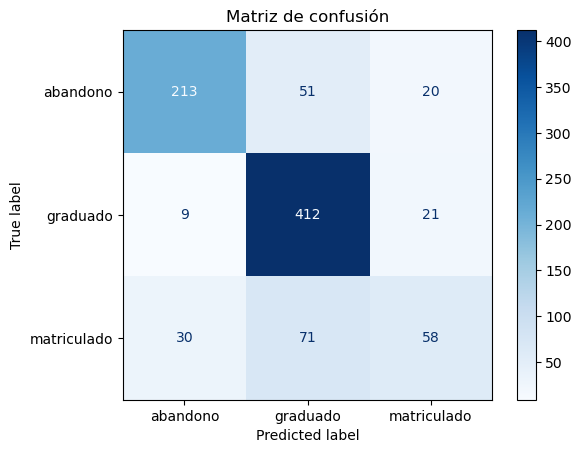

In [27]:
cm = confusion_matrix(y_test, predictions, labels=modelo_final.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=modelo_final.classes_)
disp.plot(cmap="Blues")
plt.title("Matriz de confusión")
plt.show()

Al mostrar la matriz de confusión de las variables, podemos observar que exactamente nuestras suposiciones son ciertas. La variable graduado es la que el modelo acierta con un amayor frecuencia, mientras que la variable abandono algo menos en comparación, pero la variable matriculado es predicha de manera incorrecta en muchas ocasiones.

In [28]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

    abandono       0.85      0.75      0.79       284
    graduado       0.77      0.93      0.84       442
 matriculado       0.59      0.36      0.45       159

    accuracy                           0.77       885
   macro avg       0.73      0.68      0.70       885
weighted avg       0.76      0.77      0.76       885



Dado que se trata de un problema multiclase, se han utilizado métricas como precisión, recall y F1-score para evaluar el modelo, ya que permiten analizar el rendimiento de forma más completa que la accuracy.

## 6. Importancia de las variables 
A continuación vamos a calcular la importancia que tienen cada una de las variables en la predicción de los valores

In [30]:
nombres_variables = list(ohe.get_feature_names_out(col_cat)) + list(col_num)

featureImportance = pd.DataFrame(
    {"Feature Importance": modelo_final.feature_importances_ * 100},
    index=nombres_variables
)

featureImportance = featureImportance.sort_values(
    "Feature Importance", ascending=False
).head(20)

featureImportance

,Feature Importance
curso_enfermeria,14.138087
curso_enfermeria_veterinaria,9.279137
modo_solicitud_internacional,8.246439
modo_solicitud_mayor_de_23_anos,6.230294
curso_educacion_basica,4.120641
modo_solicitud_1a_fase_contingente_general,4.072182
modo_solicitud_casos_administrativos,3.701550
asignaturas_2sem_sin_evaluacion,3.689943
modo_solicitud_1a_fase_contingente_especial_madeira,3.663708
modo_solicitud_2a_fase_contingente_general,3.618232


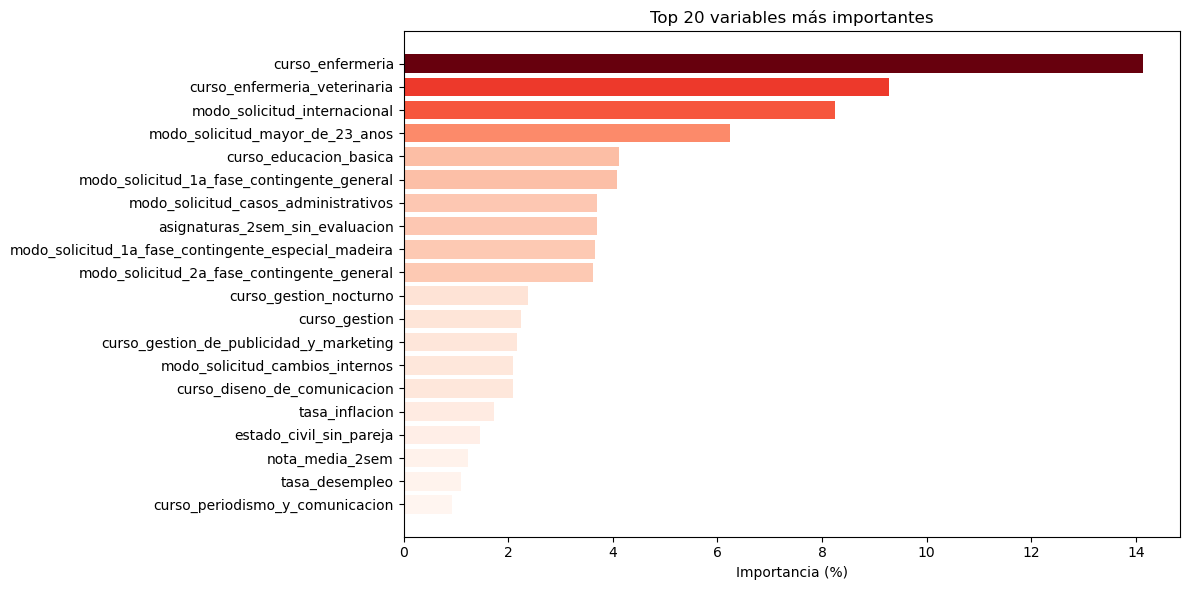

In [34]:
# Normalizo los valores y se elige el color del mapa
valores = featureImportance["Feature Importance"]
norm = plt.Normalize(valores.min(), valores.max())
colores = plt.cm.Reds(norm(valores))

# Graficamos
plt.figure(figsize=(12,6))
plt.barh(featureImportance.index[::-1], valores[::-1], color=colores[::-1])
plt.xlabel('Importancia (%)')
plt.title('Top 20 variables más importantes')
plt.tight_layout()
plt.show()

## 7. Correlaciones entre variables relevantes

Debido a que puede existir correlación entre las variables más importantes, estudiaremos su redundancia. Aunque en modelos de árboles no sean un problema tan grande puede que afecte a la manera en la que interpretamos los resultados.

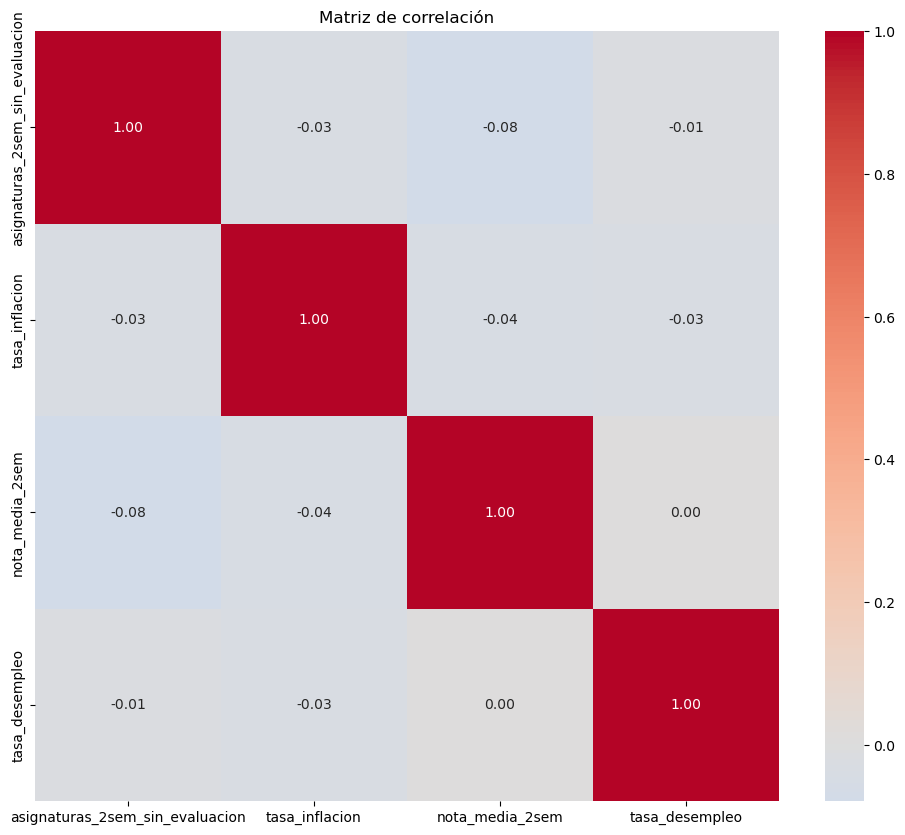

In [33]:
num_cols = [col for col in featureImportance.head(20).index if col in df.columns]

corr = df[num_cols].corr()

plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Matriz de correlación")
plt.show()

Sí que se puede observar que hay variables que tiene una correlación muy alta, como son las relativas al primer semestre contra las del segundo semestre. Con estas conclusiones podríamos plantear un nuevo modelo eliminando las dos variables y comprobar el rendimiento que mantienen. Sin embargo, Random Forest no siempre mejora la métrica aunque sí que puede mejorar la claridad de los resultados.